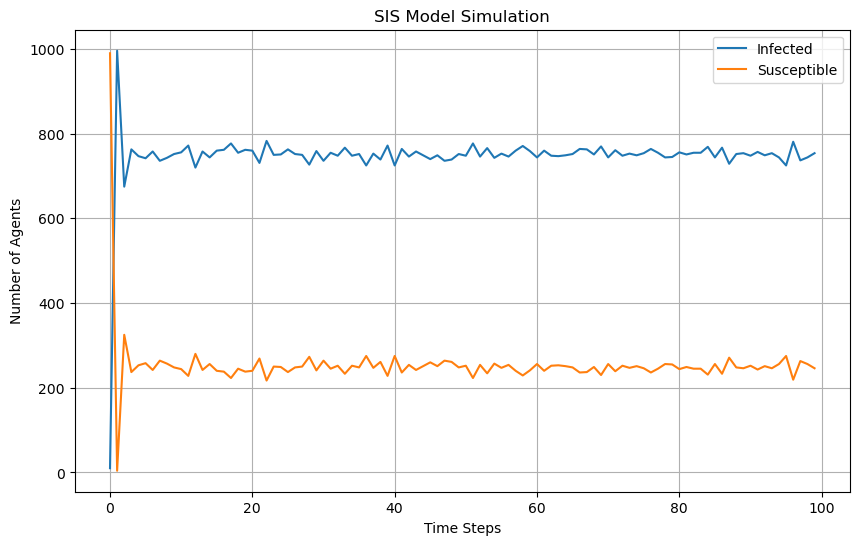

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random
from enum import Enum, auto

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

class Agent:
    def __init__(self):
        self.state = HealthState.SUSCEPTIBLE
        self.next_state = HealthState.SUSCEPTIBLE
        self.location = None
        self.next_location = None


class HealthState(Enum):
    SUSCEPTIBLE = auto()
    INFECTED = auto()


class Simulation:
    def __init__(self, total_agents=2000, N=20, initial_infected=1, average_degree=5, beta=0.0035, 
                 mu=0.1, p=0.1, alpha=0.6, steps=100):
        self.total_agents = total_agents
        self.N = N
        self.initial_infected = initial_infected
        self.beta = beta
        self.mu = mu
        self.p = p
        self.alpha = alpha
        self.steps = steps
        self.average_degree = average_degree

        self.agents = [Agent() for _ in range(total_agents)]
        self.G = nx.watts_strogatz_graph(N, average_degree, 0.8)

        # 生成小世界网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
        for u, v in self.G.edges():
            self.G[u][v]['weight'] = random.randint(1, 10)
        self.W = nx.to_numpy_array(self.G, weight='weight')

        # 计算C矩阵
        N = self.W.shape[0]
        C = np.zeros_like(self.W, dtype=float)
        for i in range(N):
            row_sum = np.sum(self.W[i, :])
            if row_sum > 0:
                C[i, :] = self.W[i, :] / row_sum
        self.C = C

    def _initialize_agents(self):
        # 随机选择初始感染者
        initial_infected = np.random.choice(self.agents, size=self.initial_infected, replace=False)
        for agent in initial_infected:
            agent.state = HealthState.INFECTED
            agent.next_state = HealthState.INFECTED

        # 将每个岛屿分配相同数量的代理
        agents_per_patch = len(self.agents) // self.N
        for patch_id in range(self.N):
            # 计算当前岛屿的起始索引-结束索引（不包括）
            for agent in self.agents[patch_id*agents_per_patch:(patch_id+1)*agents_per_patch]:
                agent.location = patch_id
                agent.next_location = patch_id

    def _update_state(self):

        rand_nums = np.random.random(len(self.agents))
        infection_probabilities = np.zeros(self.N)
        # migration_probabilities = np.zeros(self.N)

        # 计算每个patch上的代理数量以及每个岛屿上感染代理的数量
        patch_population = np.zeros(self.N)
        infected_count = np.zeros(self.N)

        for agent in self.agents:
            patch_population[agent.location] += 1
            if agent.state == HealthState.INFECTED:
                infected_count[agent.location] += 1

        # 初始感染率
        rho = infected_count / patch_population

        # 计算每个patch中的感染率
        for i in range(self.N):
            R_i = 1 - (1 - self.beta) ** ((1 - self.p) * self.average_degree * rho[i] +
                                            np.sum([self.p * self.C[j, i] * self.average_degree * rho[j] for j in range(self.N)]))
            D_i = 1 - (1 - beta) ** ((1 - self.p) * patch_population * rho[i] +
                                            np.sum([self.p * self.C[j, i] * patch_population * rho[j] for j in 
                                            range(self.N)]))
            P_i = self.alpha * R_i + (1 - self.alpha) * D_i
            # Πi = infection_probabilities
            infection_probabilities = (1 - self.p) * P_i + self.p * np.sum([self.C[i, j] * P_i for j in range(self.N)])

        # infection_probabilities = self.beta * (infected_count / patch_population)
        # migration_probabilities = self.p * (infected_count / patch_population)
        # 生成一个元组序列，索引赋值给i，代理对象赋值给agent
        for i, agent in enumerate(self.agents):
            if agent.state == HealthState.SUSCEPTIBLE:
                if rand_nums[i] < infection_probabilities[agent.location]:
                    agent.next_state = HealthState.INFECTED
                # if rand_nums[i] < migration_probabilities[agent.location]:
                #     neighbors = list(self.G.neighbors(agent.location))
                #     if neighbors:
                #         agent.next_location = np.random.choice(neighbors)
            elif agent.state == HealthState.INFECTED and rand_nums[i] < self.mu:
                agent.next_state = HealthState.SUSCEPTIBLE
            else:
                agent.next_state = agent.state
                agent.next_location = agent.location

        for agent in self.agents:
            agent.state = agent.next_state
            agent.location = agent.next_location

    def _run_simulation(self):
        time_steps = 100
        infected_history = []
        susceptible_history = []

        for _ in range(time_steps):
            infected_count = sum(agent.state == HealthState.INFECTED for agent in self.agents)
            susceptible_count = sum(agent.state == HealthState.SUSCEPTIBLE for agent in self.agents)
            
            infected_history.append(infected_count)
            susceptible_history.append(susceptible_count)

            self._update_state()

        return infected_history, susceptible_history

    def run(self):
        self._initialize_agents()
        infected_history, susceptible_history = self._run_simulation()
        self._plot_results(infected_history, susceptible_history)

    def _plot_results(self, infected_history, susceptible_history):
        plt.figure(figsize=(10, 6))
        plt.plot(infected_history, label='Infected')
        plt.plot(susceptible_history, label='Susceptible')
        plt.xlabel('Time Steps')
        plt.ylabel('Number of Agents')
        plt.title('SIS Model Simulation')
        plt.legend()
        plt.grid(True)
        plt.show()


# 参数配置
total_agents = 1000
N = 20
average_degree = 8
initial_infected = 10
beta = 0.833
mu = 0.33
p = 0.2

# 运行模拟
simulation = Simulation(
    total_agents=total_agents,
    N=N,
    initial_infected=initial_infected,
    average_degree=average_degree,
    beta=beta,
    mu=mu,
    p=p
)
simulation.run()
